In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import poisson, chi2

In [10]:
# Load the cleaned invoice-level dataset
invoices = pd.read_csv("data/final_invoice_level.csv")

# Display the dataset dimensions
print("Dataset shape:", invoices.shape)

# Display the first five rows
display(invoices.head())

Dataset shape: (36594, 13)


,InvoiceYear,InvoiceNo,CustomerID,Country,InvoiceDate,InvoiceMonth,InvoiceAmount,ItemQuantity,ProductLineCount,DistinctProducts,PossibleDuplicateLineCount,HighInvoiceAmountFlag,InvoiceTimestampSpreadMinutes
0,2009,489434,13085,United Kingdom,2009-12-01 07:45:00,2009-12,505.30,166,8,8,0,False,0.0
1,2009,489435,13085,United Kingdom,2009-12-01 07:46:00,2009-12,145.80,60,4,4,0,False,0.0
2,2009,489436,13078,United Kingdom,2009-12-01 09:06:00,2009-12,630.33,193,19,19,0,False,0.0
3,2009,489437,15362,United Kingdom,2009-12-01 09:08:00,2009-12,310.75,145,23,23,0,False,0.0
4,2009,489438,18102,United Kingdom,2009-12-01 09:24:00,2009-12,2286.24,826,17,17,0,False,0.0


In [11]:
# Check the data types of important columns
print("Column data types:")
print(invoices[["CustomerID", "InvoiceNo", "InvoiceDate"]].dtypes)

# Check missing values
print("\nMissing values:")
print(invoices[["CustomerID", "InvoiceNo", "InvoiceDate"]].isnull().sum())

Column data types:
CustomerID     int64
InvoiceNo      int64
InvoiceDate      str
dtype: object

Missing values:
CustomerID     0
InvoiceNo      0
InvoiceDate    0
dtype: int64


In [12]:
# Convert InvoiceDate into datetime format
invoices["InvoiceDate"] = pd.to_datetime(invoices["InvoiceDate"])

# Check whether conversion was successful
print("New data type:")
print(invoices["InvoiceDate"].dtype)

# Check the date range
print("\nFirst purchase date:")
print(invoices["InvoiceDate"].min())

print("\nLast purchase date:")
print(invoices["InvoiceDate"].max())

New data type:
datetime64[us]

First purchase date:
2009-12-01 07:45:00

Last purchase date:
2011-12-09 12:50:00


In [13]:
# Extract month and year from InvoiceDate
invoices["InvoiceMonth"] = invoices["InvoiceDate"].dt.to_period("M")

# Display the first five rows
display(invoices[["CustomerID", "InvoiceNo", "InvoiceDate", "InvoiceMonth"]].head())

# Check the number of different months
print("Total months:", invoices["InvoiceMonth"].nunique())

,CustomerID,InvoiceNo,InvoiceDate,InvoiceMonth
0,13085,489434,2009-12-01 07:45:00,2009-12
1,13085,489435,2009-12-01 07:46:00,2009-12
2,13078,489436,2009-12-01 09:06:00,2009-12
3,15362,489437,2009-12-01 09:08:00,2009-12
4,18102,489438,2009-12-01 09:24:00,2009-12


Total months: 25


In [14]:
# Keep complete analysis months
analysis_invoices = invoices[
    invoices["InvoiceMonth"] <= pd.Period("2011-11", freq="M")
].copy()

# Check the selected period
print("First month:", analysis_invoices["InvoiceMonth"].min())
print("Last month:", analysis_invoices["InvoiceMonth"].max())

print("Total months:", analysis_invoices["InvoiceMonth"].nunique())
print("Total invoices:", analysis_invoices["InvoiceNo"].nunique())

First month: 2009-12
Last month: 2011-11
Total months: 24
Total invoices: 35818


In [15]:
# Check date coverage in the first and last calendar months
boundary_check = invoices[
    invoices["InvoiceMonth"].isin([
        pd.Period("2009-12", freq="M"),
        pd.Period("2011-12", freq="M")
    ])
].groupby("InvoiceMonth")["InvoiceDate"].agg(["min", "max"])

display(boundary_check)

,min,max
InvoiceMonth,,
2009-12,2009-12-01 07:45:00,2009-12-23 16:58:00
2011-12,2011-12-01 08:33:00,2011-12-09 12:50:00


In [16]:
# Retain December 2009 to November 2011
analysis_invoices = invoices[
    invoices["InvoiceMonth"] <= pd.Period("2011-11", freq="M")
].copy()

# Check our final analysis period
print("First month:", analysis_invoices["InvoiceMonth"].min())
print("Last month:", analysis_invoices["InvoiceMonth"].max())

print("Total months:", analysis_invoices["InvoiceMonth"].nunique())
print("Total invoices:", analysis_invoices["InvoiceNo"].nunique())

First month: 2009-12
Last month: 2011-11
Total months: 24
Total invoices: 35818


In [17]:
# Count unique invoices for each customer in each month
monthly_counts = (
    analysis_invoices
    .groupby(["CustomerID", "InvoiceMonth"])["InvoiceNo"]
    .nunique()
    .reset_index(name="PurchaseCount")
)

# Display the first 10 records
display(monthly_counts.head(10))

# Check the total number of customer-month records
print("Total customer-month records:", len(monthly_counts))

,CustomerID,InvoiceMonth,PurchaseCount
0,12346,2010-03,1
1,12346,2010-06,1
2,12346,2011-01,1
3,12347,2010-10,1
4,12347,2010-12,1
5,12347,2011-01,1
6,12347,2011-04,1
7,12347,2011-06,1
8,12347,2011-08,1
9,12347,2011-10,1


Total customer-month records: 24889


In [18]:
# Find each customer's first and last purchase month
customer_periods = monthly_counts.groupby("CustomerID")["InvoiceMonth"].agg(
    first_month="min",
    last_month="max"
)

# Create every month between first and last purchase
customer_month_rows = []

for customer, row in customer_periods.iterrows():
    months = pd.period_range(
        start=row["first_month"],
        end=row["last_month"],
        freq="M"
    )

    for month in months:
        customer_month_rows.append((customer, month))

# Convert the generated records into a DataFrame
customer_month_panel = pd.DataFrame(
    customer_month_rows,
    columns=["CustomerID", "InvoiceMonth"]
)

# Add actual purchase counts
customer_month_panel = customer_month_panel.merge(
    monthly_counts,
    on=["CustomerID", "InvoiceMonth"],
    how="left"
)

# Replace missing purchase counts with zero
customer_month_panel["PurchaseCount"] = (
    customer_month_panel["PurchaseCount"].fillna(0).astype(int)
)

# Display the result
display(customer_month_panel.head(15))

print("Total customer-month records:", len(customer_month_panel))
print("Zero-purchase months:", (customer_month_panel["PurchaseCount"] == 0).sum())

,CustomerID,InvoiceMonth,PurchaseCount
0,12346,2010-03,1
1,12346,2010-04,0
2,12346,2010-05,0
3,12346,2010-06,1
4,12346,2010-07,0
5,12346,2010-08,0
6,12346,2010-09,0
7,12346,2010-10,0
8,12346,2010-11,0
9,12346,2010-12,0


Total customer-month records: 56944
Zero-purchase months: 32055


In [19]:
# Extract monthly purchase counts
purchase_counts = customer_month_panel["PurchaseCount"]

# Calculate mean and variance
mean_count = purchase_counts.mean()
variance_count = purchase_counts.var()

# Calculate dispersion ratio
dispersion_ratio = variance_count / mean_count

# Display the results
print("Mean:", mean_count)
print("Variance:", variance_count)
print("Dispersion Ratio:", dispersion_ratio)

Mean: 0.6290039336892386
Variance: 1.2449350596757962
Dispersion Ratio: 1.979216651911847


In [20]:
# Estimate Poisson parameter lambda
lambda_hat = purchase_counts.mean()

print("Estimated Poisson Lambda:", lambda_hat)

Estimated Poisson Lambda: 0.6290039336892386


In [21]:
# Find the maximum number of monthly purchases
max_count = int(purchase_counts.max())

# Create possible purchase counts: 0, 1, 2, 3, ...
x_values = np.arange(max_count + 1)

# Calculate Poisson probabilities
probabilities = poisson.pmf(x_values, mu=lambda_hat)

# Calculate the probability of counts above the observed maximum
tail_probability = poisson.sf(max_count, mu=lambda_hat)

# Display the probabilities
poisson_table = pd.DataFrame({
    "Purchase Count": x_values,
    "Poisson Probability": probabilities
})

display(poisson_table)

print("Maximum observed purchase count:", max_count)
print("Probability above maximum:", tail_probability)
print("Sum of displayed probabilities and tail:",
      probabilities.sum() + tail_probability)

,Purchase Count,Poisson Probability
0,0,5.331226e-01
1,1,3.353362e-01
2,2,1.054639e-01
3,3,2.211240e-02
4,4,3.477197e-03
5,5,4.374341e-04
6,6,4.585796e-05
7,7,4.120691e-06
8,8,3.239914e-07
9,9,2.264354e-08


Maximum observed purchase count: 44
Probability above maximum: 3.9300150285335673e-66
Sum of displayed probabilities and tail: 1.0


In [22]:
# Total number of customer-month observations
n = len(purchase_counts)

# Calculate observed frequencies
observed = purchase_counts.value_counts().reindex(
    x_values, fill_value=0
).sort_index()

# Calculate expected frequencies using Poisson probabilities
expected = n * probabilities

# Include the upper-tail category
observed_tail = (purchase_counts > max_count).sum()
expected_tail = n * tail_probability

# Create comparison table
comparison_table = pd.DataFrame({
    "Purchase Count": [str(x) for x in x_values] + [f">{max_count}"],
    "Observed Frequency": list(observed) + [observed_tail],
    "Expected Frequency": list(expected) + [expected_tail]
})

display(comparison_table)

print("Total observations:", n)
print("Total observed frequency:", comparison_table["Observed Frequency"].sum())
print("Total expected frequency:", comparison_table["Expected Frequency"].sum())

,Purchase Count,Observed Frequency,Expected Frequency
0,0,32055,3.035813e+04
1,1,18862,1.909538e+04
2,2,3968,6.005536e+03
3,3,1141,1.259169e+03
4,4,399,1.980055e+02
5,5,179,2.490925e+01
6,6,125,2.611336e+00
7,7,50,2.346486e-01
8,8,40,1.844936e-02
9,9,28,1.289414e-03


Total observations: 56944
Total observed frequency: 56944
Total expected frequency: 56944.0


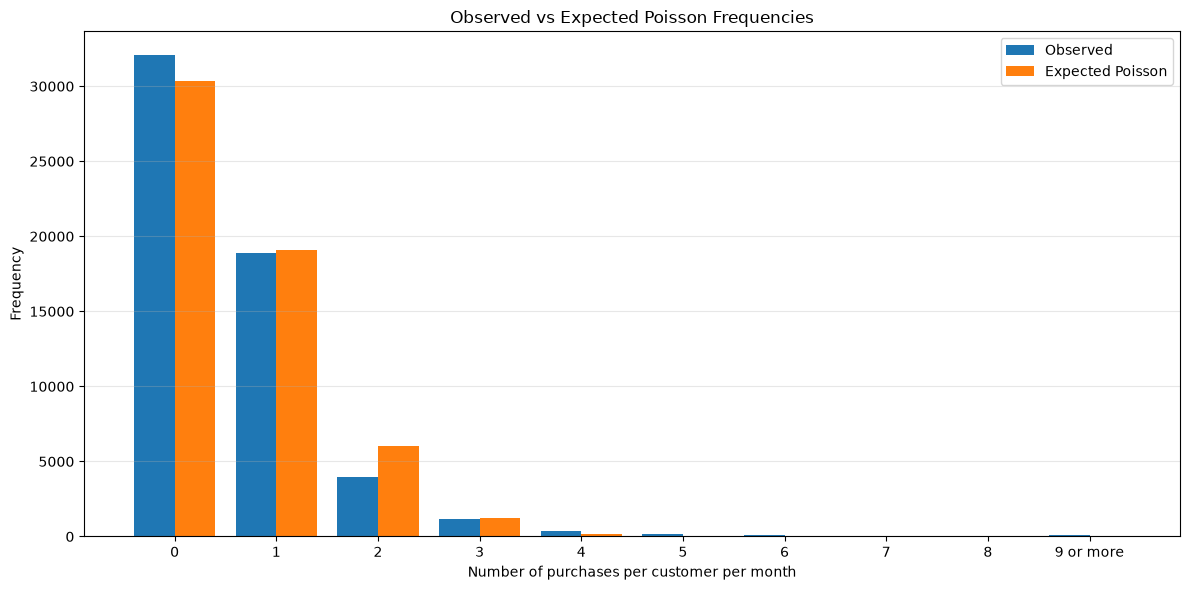

In [23]:
# Group purchase counts into 0 to 8 and 9 or more
observed_grouped = [
    (purchase_counts == x).sum() for x in range(9)
]

observed_grouped.append((purchase_counts >= 9).sum())

expected_grouped = [
    n * poisson.pmf(x, mu=lambda_hat) for x in range(9)
]

expected_grouped.append(
    n * poisson.sf(8, mu=lambda_hat)
)

# Create comparison graph
labels = [str(x) for x in range(9)] + ["9 or more"]

positions = np.arange(len(labels))
width = 0.4

plt.figure(figsize=(12, 6))

plt.bar(
    positions - width/2,
    observed_grouped,
    width,
    label="Observed"
)

plt.bar(
    positions + width/2,
    expected_grouped,
    width,
    label="Expected Poisson"
)

plt.xticks(positions, labels)
plt.xlabel("Number of purchases per customer per month")
plt.ylabel("Frequency")
plt.title("Observed vs Expected Poisson Frequencies")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Combine adjacent categories with expected frequency below 5

observed_all = np.append(observed.to_numpy(), observed_tail)
expected_all = np.append(expected, expected_tail)

labels_all = [str(x) for x in x_values] + [f">{max_count}"]

grouped = []
group_observed = 0
group_expected = 0
group_start = None
group_end = None

for label, obs, exp in zip(labels_all, observed_all, expected_all):

    if group_start is None:
        group_start = label

    group_end = label
    group_observed += obs
    group_expected += exp

    if group_expected >= 5:
        grouped.append([
            group_start, group_end,
            group_observed, group_expected
        ])

        group_observed = 0
        group_expected = 0
        group_start = None

# Merge any remaining small group with the previous group
if group_expected > 0:
    grouped[-1][1] = group_end
    grouped[-1][2] += group_observed
    grouped[-1][3] += group_expected

# Create grouped frequency table
grouped_table = pd.DataFrame(
    grouped,
    columns=[
        "Starting Category",
        "Ending Category",
        "Observed",
        "Expected"
    ]
)

display(grouped_table)

,Starting Category,Ending Category,Observed,Expected
0,0,0,32055,30358.131173
1,1,1,18862,19095.383928
2,2,2,3968,6005.535803
3,3,3,1141,1259.168548
4,4,4,399,198.005492
5,5,>44,519,27.775056


In [25]:
# Step 1: Calculate Chi-square statistic

chi_square_stat = (
    (grouped_table["Observed"] - grouped_table["Expected"])**2
    / grouped_table["Expected"]
).sum()

# Step 2: Calculate degrees of freedom

number_of_groups = len(grouped_table)
estimated_parameters = 1  # Lambda estimated from the data

df = number_of_groups - 1 - estimated_parameters

# Step 3: Calculate p-value

p_value = chi2.sf(chi_square_stat, df)

# Step 4: Display results

print("Chi-square statistic:", chi_square_stat)
print("Degrees of freedom:", df)
print("P-value:", p_value)

# Step 5: Make the decision

if p_value < 0.05:
    print("\nDecision: Reject H0")
    print("Conclusion: Poisson does not adequately fit the data.")
else:
    print("\nDecision: Fail to reject H0")
    print("Conclusion: No significant evidence of lack of fit.")

Chi-square statistic: 9691.826220848709
Degrees of freedom: 4
P-value: 0.0

Decision: Reject H0
Conclusion: Poisson does not adequately fit the data.


In [26]:
# Calculate Poisson log-likelihood

log_likelihood = poisson.logpmf(
    purchase_counts,
    mu=lambda_hat
).sum()

# Number of estimated parameters
k = 1

# Calculate AIC
aic = 2 * k - 2 * log_likelihood

print("Log-likelihood:", log_likelihood)
print("AIC:", aic)

Log-likelihood: -64145.29251225259
AIC: 128292.58502450518
